In [1]:
# Parameters
ticker = "AAPL"
start_date = "2024-01-01"
end_date = "2024-12-31"
db_path = "data/data.db"
metrics_path = ""

# Single-Stock Risk Report

This parameterized notebook analyzes a single ticker from the locally cleaned SQLite table. The requested dates are inclusive; all returns use adjusted close and daily log returns. Metrics stay in fractions until formatted for display.

In [7]:
from pathlib import Path
import json
import math
import sqlite3

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection, PolyCollection
import numpy as np
import pandas as pd
from IPython.display import display

TICKER = str(ticker).strip().upper()
START = pd.Timestamp(start_date).normalize()
END = pd.Timestamp(end_date).normalize()
if not TICKER:
    raise ValueError("ticker must be a non-empty string.")
if START > END:
    raise ValueError("start_date must be on or before end_date.")

NOTEBOOK_DIR = Path.cwd()
if NOTEBOOK_DIR.name != "Mrityunjay_Balkrishnan":
    candidate_dir = NOTEBOOK_DIR / "Homeworks" / "HW2" / "Mrityunjay_Balkrishnan"
    if candidate_dir.is_dir():
        NOTEBOOK_DIR = candidate_dir

requested_db = Path(db_path).expanduser()
if requested_db.is_absolute():
    db_candidates = [requested_db]
else:
    db_candidates = [NOTEBOOK_DIR / requested_db, Path.cwd() / requested_db]
    if requested_db == Path("data/data.db"):
        db_candidates.append(NOTEBOOK_DIR / "data" / "data.db")

def has_clean_table(candidate: Path) -> bool:
    """Check local SQLite metadata read-only; do not create an empty DB."""
    if not candidate.is_file():
        return False
    try:
        with sqlite3.connect(f"file:{candidate.resolve()}?mode=ro", uri=True) as check_conn:
            found = pd.read_sql_query(
                "SELECT 1 FROM sqlite_master WHERE type='table' AND name='ohlc_hw_cleaned'",
                check_conn,
            )
        return not found.empty
    except sqlite3.Error:
        return False

DB_PATH = next((candidate.resolve() for candidate in db_candidates if has_clean_table(candidate)), None)
if DB_PATH is None:
    raise FileNotFoundError(
        "Could not find a database containing ohlc_hw_cleaned. Run 01_data_cleaning.ipynb first; "
        f"checked: {[str(path) for path in db_candidates]}"
    )

sql = (
    "SELECT ts, ticker, open, high, low, close, adj_close, volume "
    "FROM ohlc_hw_cleaned WHERE ticker = ? AND ts >= ? AND ts <= ? ORDER BY ts"
)
with sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True) as conn:
    report_data = pd.read_sql_query(
        sql,
        conn,
        params=(TICKER, START.strftime("%Y-%m-%d"), END.strftime("%Y-%m-%d")),
        parse_dates=["ts"],
    )

if report_data.empty:
    raise ValueError(f"No cleaned observations for {TICKER} from {START.date()} through {END.date()}.")
report_data = report_data.sort_values("ts").reset_index(drop=True)
if report_data["ts"].duplicated().any():
    raise ValueError(f"Duplicate dates found for {TICKER}; rerun cleaning and inspect the cleaned key validation.")
if len(report_data) < 21:
    raise ValueError(f"Insufficient history for a 20-return rolling estimate: {TICKER} has {len(report_data)} prices; at least 21 are required.")
price_values = report_data["adj_close"].to_numpy(dtype=float)
if not np.isfinite(price_values).all() or not (price_values > 0).all():
    raise ValueError("Cleaned adjusted-close series contains missing, non-finite, or nonpositive values.")

actual_start = report_data["ts"].iloc[0]
actual_end = report_data["ts"].iloc[-1]
print(f"{TICKER} from {START.date()} to {END.date()}: {len(report_data):,} trading days")
print(f"Actual coverage: {actual_start.date()} through {actual_end.date()}")
display(report_data.head())
display(report_data.tail())

AAPL from 2024-01-01 to 2024-12-31: 202 trading days
Actual coverage: 2024-01-02 through 2024-10-18


,ts,ticker,open,high,low,close,adj_close,volume
0,2024-01-02,AAPL,187.15,188.44,183.89,185.64,184.94,82488674
1,2024-01-03,AAPL,184.22,185.88,183.43,184.25,183.55,58414460
2,2024-01-04,AAPL,182.15,183.09,180.88,181.91,181.22,71983570
3,2024-01-05,AAPL,181.99,182.76,180.17,181.18,180.50,62379661
4,2024-01-08,AAPL,182.09,185.60,181.50,185.56,184.86,59144470


,ts,ticker,open,high,low,close,adj_close,volume
197,2024-10-14,AAPL,228.70,231.73,228.60,231.30,231.30,39882100
198,2024-10-15,AAPL,233.61,237.49,232.37,233.85,233.85,64751400
199,2024-10-16,AAPL,231.60,232.12,229.84,231.78,231.78,34082240
200,2024-10-17,AAPL,233.43,233.85,230.52,232.15,232.15,32993810
201,2024-10-18,AAPL,236.18,236.18,234.01,235.00,235.00,45441281


## Risk metric definitions

The required calculations use **daily log returns** from adjusted close. A 20-day rolling standard deviation requires 20 returns (21 prices); warm-up estimates remain missing. Drawdown is the recoverable per-date distance from the running peak, while maximum drawdown is its minimum.

In [8]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns from a positive price series."""
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling sample volatility of daily log returns."""
    if not isinstance(window, int) or window < 2:
        raise ValueError("window must be an integer of at least 2 returns.")
    return returns.rolling(window=window, min_periods=window).std(ddof=1) * np.sqrt(252)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running adjusted-price peak."""
    running_peak = prices.cummax()
    return prices.div(running_peak).sub(1.0)


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Return annualized course-approximation Sharpe, or NaN if undefined."""
    valid_returns = returns.replace([np.inf, -np.inf], np.nan).dropna()
    if len(valid_returns) < 2:
        return float("nan")
    daily_std = valid_returns.std(ddof=1)
    if not np.isfinite(daily_std) or daily_std == 0:
        return float("nan")
    return float((valid_returns.mean() * 252 - risk_free_rate) / (daily_std * np.sqrt(252)))


adj_close = report_data["adj_close"].astype(float).set_axis(report_data["ts"])
log_returns = calculate_returns(adj_close)
rolling_volatility = calculate_volatility(log_returns, window=20)
drawdown = calculate_max_drawdown(adj_close)
max_drawdown = float(drawdown.min())
sharpe_ratio = calculate_sharpe_ratio(log_returns, risk_free_rate=0.02)

# Hand-computable checks protect definitions from accidental changes.
tiny_prices = pd.Series([50.0, 55.0, 44.0])
np.testing.assert_allclose(calculate_returns(tiny_prices).dropna(), [np.log(1.1), np.log(0.8)])
np.testing.assert_allclose(calculate_max_drawdown(pd.Series([100.0, 120.0, 90.0, 108.0])), [0.0, 0.0, -0.25, -0.10])
assert np.isnan(calculate_sharpe_ratio(pd.Series([0.01, 0.01, 0.01])))
print(f"Daily log-return observations: {log_returns.notna().sum()}")
print(f"20-return rolling volatility available: {rolling_volatility.notna().sum()}")
print(f"Maximum drawdown: {max_drawdown:.4%}; Sharpe: {sharpe_ratio:.3f}")

Daily log-return observations: 201
20-return rolling volatility available: 182
Maximum drawdown: -15.3518%; Sharpe: 1.187


## Four-panel risk visualization

The left price panel colors the adjusted-price line by the rolling-volatility estimate available at each date (retrospective coloring). Gray indicates warm-up dates. The moving average and rolling volatility retain their missing warm-up periods instead of filling with zero.

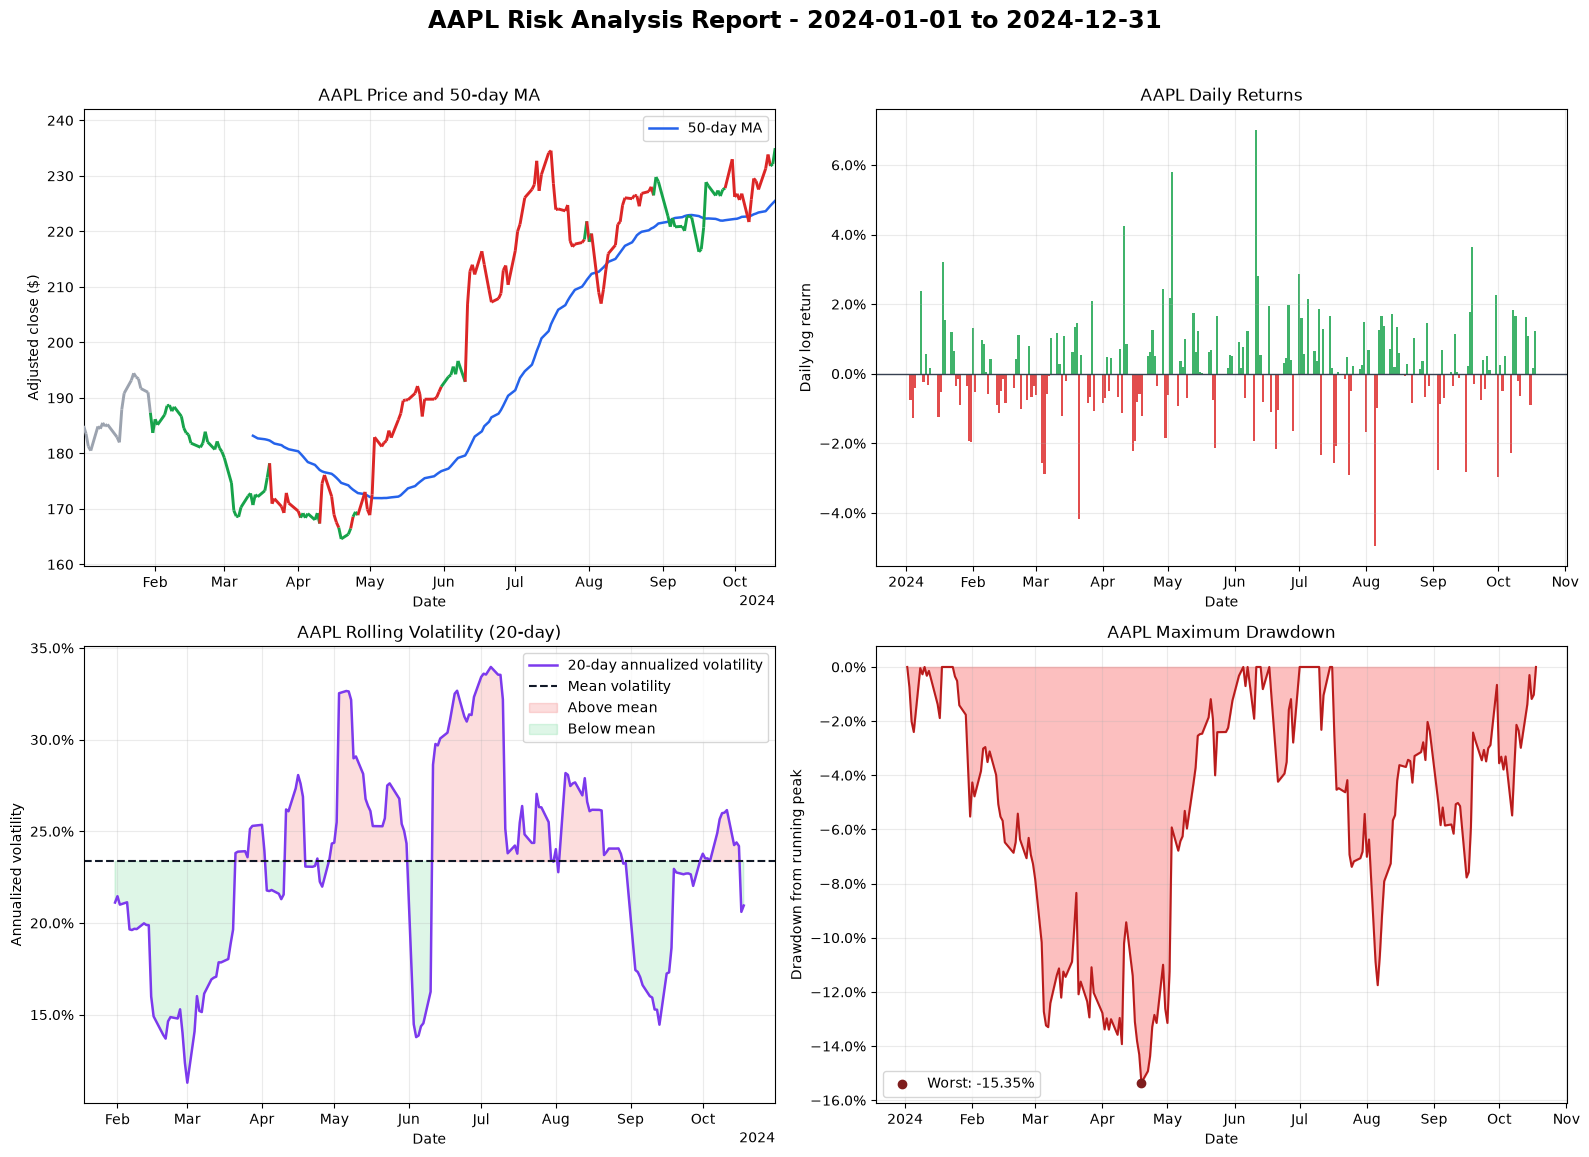

50-day MA available from 2024-03-13.


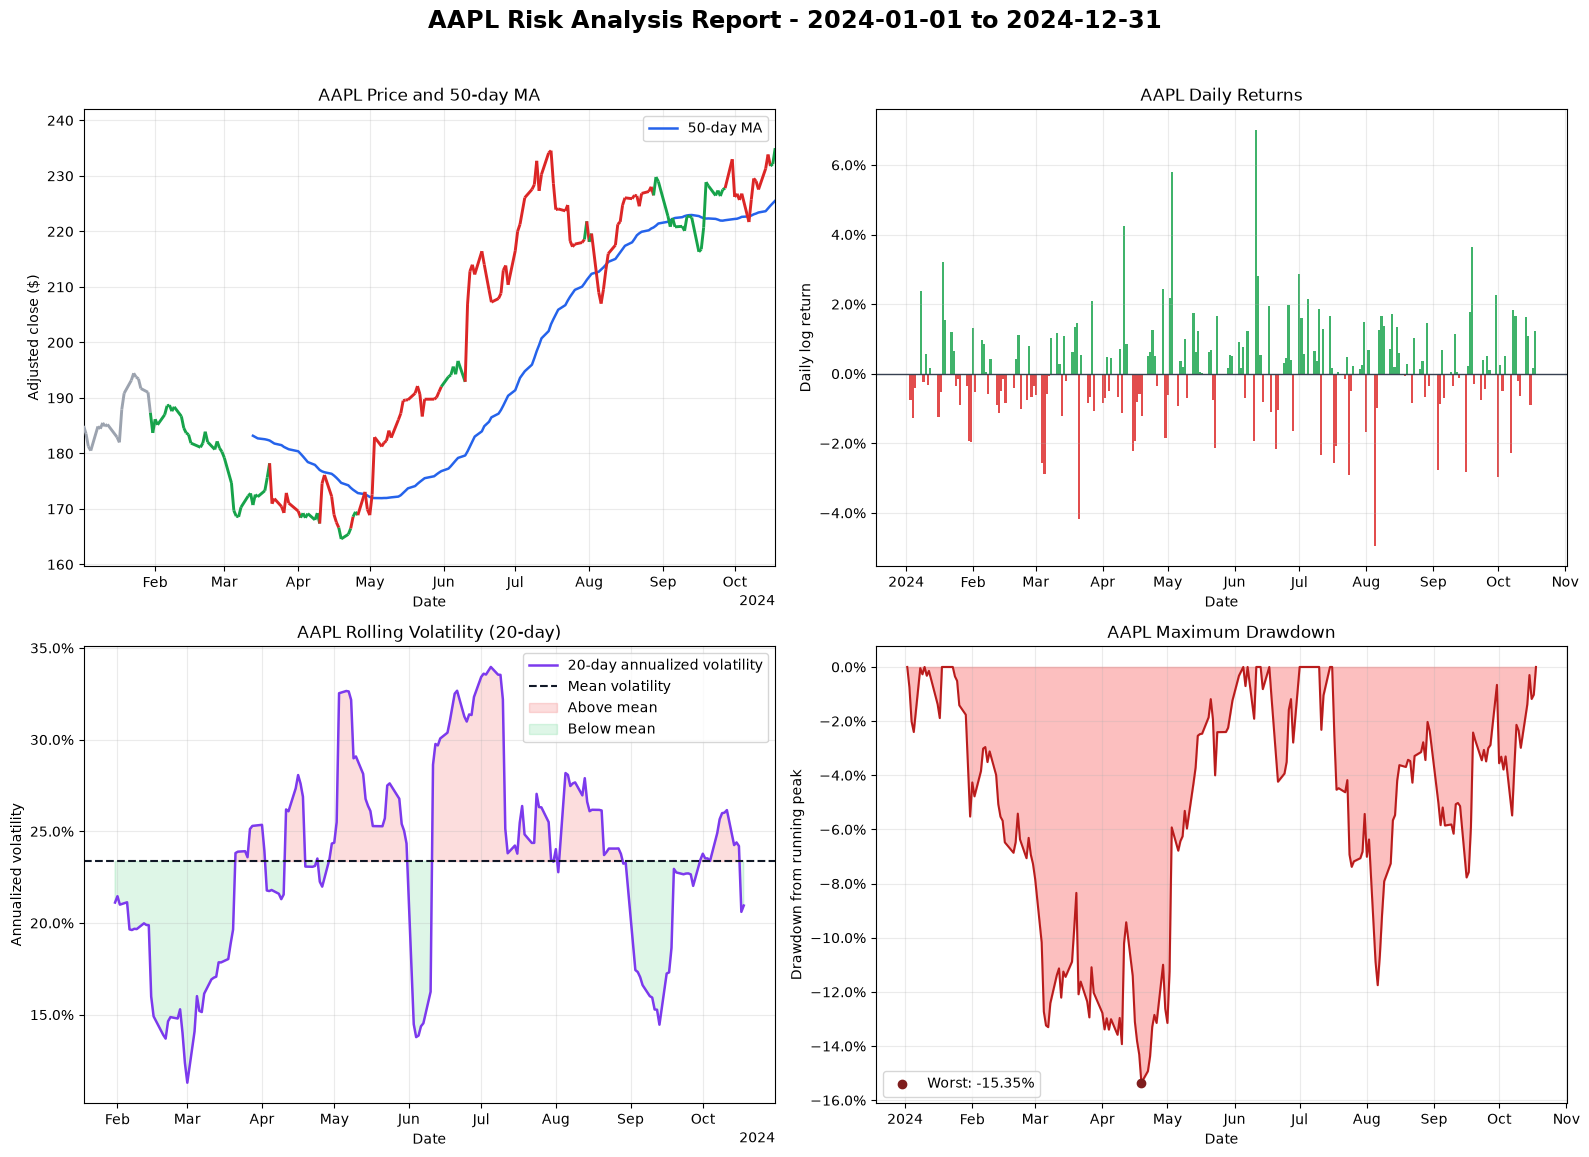

In [9]:
from matplotlib.ticker import PercentFormatter

moving_average_50 = adj_close.rolling(window=50, min_periods=50).mean()
mean_rolling_volatility = rolling_volatility.mean()
figure, axes = plt.subplots(2, 2, figsize=(16, 12))
ax_price, ax_returns, ax_volatility, ax_drawdown = axes.ravel()

# Color each price segment by the rolling-volatility state at its ending date.
x_values = mdates.date2num(report_data["ts"].dt.to_pydatetime())
y_values = adj_close.to_numpy(dtype=float)
points = np.column_stack([x_values, y_values])
segments = np.stack([points[:-1], points[1:]], axis=1)
segment_vol = rolling_volatility.iloc[1:].to_numpy(dtype=float)
if np.isfinite(mean_rolling_volatility):
    segment_colors = [
        "#9ca3af" if not np.isfinite(value) else ("#dc2626" if value > mean_rolling_volatility else "#16a34a")
        for value in segment_vol
    ]
else:
    segment_colors = ["#9ca3af"] * len(segments)
price_line = LineCollection(segments, colors=segment_colors, linewidths=2.1, zorder=3)
ax_price.add_collection(price_line)
ax_price.plot(report_data["ts"], moving_average_50, color="#2563eb", linewidth=1.8, label="50-day MA")
ax_price.set_xlim(report_data["ts"].min(), report_data["ts"].max())
ax_price.set_ylim(np.nanmin(y_values) * 0.97, np.nanmax(y_values) * 1.03)
ax_price.set_title(f"{TICKER} Price and 50-day MA")
ax_price.set_ylabel("Adjusted close ($)")
ax_price.legend(loc="best")

return_colors = np.where(log_returns.fillna(0).to_numpy() >= 0, "#16a34a", "#dc2626")
ax_returns.bar(report_data["ts"], log_returns.fillna(0), color=return_colors, width=1.0, alpha=0.82)
ax_returns.axhline(0, color="#374151", linewidth=1)
ax_returns.set_title(f"{TICKER} Daily Returns")
ax_returns.set_ylabel("Daily log return")
ax_returns.yaxis.set_major_formatter(PercentFormatter(xmax=1))

ax_volatility.plot(report_data["ts"], rolling_volatility, color="#7c3aed", linewidth=1.8, label="20-day annualized volatility")
if np.isfinite(mean_rolling_volatility):
    ax_volatility.axhline(mean_rolling_volatility, color="#111827", linestyle="--", label="Mean volatility")
    high_vol = rolling_volatility > mean_rolling_volatility
    low_vol = rolling_volatility < mean_rolling_volatility
    ax_volatility.fill_between(report_data["ts"], rolling_volatility, mean_rolling_volatility, where=high_vol, color="#ef4444", alpha=0.18, interpolate=True, label="Above mean")
    ax_volatility.fill_between(report_data["ts"], rolling_volatility, mean_rolling_volatility, where=low_vol, color="#22c55e", alpha=0.15, interpolate=True, label="Below mean")
ax_volatility.set_title(f"{TICKER} Rolling Volatility (20-day)")
ax_volatility.set_ylabel("Annualized volatility")
ax_volatility.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax_volatility.legend(loc="best")

drawdown_values = drawdown.to_numpy(dtype=float)
drawdown_depth = max(float(np.nanmax(np.abs(drawdown_values))), 1e-12)
drawdown_polygons = [
    [(x_values[i], 0.0), (x_values[i], drawdown_values[i]),
     (x_values[i + 1], drawdown_values[i + 1]), (x_values[i + 1], 0.0)]
    for i in range(len(drawdown_values) - 1)
]
segment_depth = np.clip(
    -(drawdown_values[:-1] + drawdown_values[1:]) / (2 * drawdown_depth), 0, 1
)
drawdown_fill = PolyCollection(
    drawdown_polygons, array=segment_depth, cmap="Reds",
    clim=(0, 1), edgecolors="none", alpha=0.72,
)
ax_drawdown.add_collection(drawdown_fill)
ax_drawdown.plot(report_data["ts"], drawdown, color="#b91c1c", linewidth=1.5)
worst_date = drawdown.idxmin()
ax_drawdown.scatter([worst_date], [drawdown.loc[worst_date]], color="#7f1d1d", zorder=5, label=f"Worst: {drawdown.loc[worst_date]:.2%}")
ax_drawdown.set_title(f"{TICKER} Maximum Drawdown")
ax_drawdown.set_ylabel("Drawdown from running peak")
ax_drawdown.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax_drawdown.legend(loc="best")

for axis in axes.ravel():
    axis.set_xlabel("Date")
    axis.grid(True, alpha=0.25)
    axis.xaxis.set_major_locator(mdates.AutoDateLocator())
    axis.xaxis.set_major_formatter(mdates.ConciseDateFormatter(axis.xaxis.get_major_locator()))
figure.suptitle(f"{TICKER} Risk Analysis Report - {start_date} to {end_date}", fontsize=17, fontweight="bold")
figure.tight_layout(rect=[0, 0.02, 1, 0.96])
display(figure)
if moving_average_50.notna().any():
    print(f"50-day MA available from {moving_average_50.first_valid_index().date()}.")
else:
    print("The 50-day MA is unavailable: fewer than 50 prices are in this report window.")

## Summary statistics

Annualized return compounds daily log returns over 252 trading days. Whole-period volatility uses the sample standard deviation of daily log returns and is distinct from the mean rolling volatility used by the portfolio summary. Empty up/down subsets and undefined Sharpe estimates display as `N/A`.

In [10]:
valid_returns = log_returns.replace([np.inf, -np.inf], np.nan).dropna()
return_count = len(valid_returns)
first_adj_close = float(adj_close.iloc[0])
last_adj_close = float(adj_close.iloc[-1])
total_return = last_adj_close / first_adj_close - 1.0
annualized_return = float(np.exp(valid_returns.sum() * 252 / return_count) - 1.0) if return_count else float("nan")
annualized_volatility = float(valid_returns.std(ddof=1) * np.sqrt(252)) if return_count >= 2 else float("nan")
best_day = float(valid_returns.max()) if return_count else float("nan")
worst_day = float(valid_returns.min()) if return_count else float("nan")
positive_days = float(valid_returns.gt(0).sum() / return_count) if return_count else float("nan")
up_days = valid_returns[valid_returns > 0]
down_days = valid_returns[valid_returns < 0]
average_up_day = float(up_days.mean()) if not up_days.empty else float("nan")
average_down_day = float(down_days.mean()) if not down_days.empty else float("nan")


def format_percent(value: float) -> str:
    """Format a fractional value for display while keeping source metrics fractional."""
    return f"{value:+.2%}" if np.isfinite(value) else "N/A"


def format_number(value: float, digits: int = 2) -> str:
    """Format finite values for display or return N/A when undefined."""
    return f"{value:.{digits}f}" if np.isfinite(value) else "N/A"


summary_table = pd.DataFrame(
    [
        ("Total Return", format_percent(total_return)),
        ("Annualized Return", format_percent(annualized_return)),
        ("Annualized Volatility", format_percent(annualized_volatility)),
        ("Sharpe Ratio", format_number(sharpe_ratio)),
        ("Maximum Drawdown", format_percent(max_drawdown)),
        ("Best Day", format_percent(best_day)),
        ("Worst Day", format_percent(worst_day)),
        ("Positive Days", format_percent(positive_days)),
        ("Average Up Day", format_percent(average_up_day)),
        ("Average Down Day", format_percent(average_down_day)),
    ],
    columns=["Metric", "Value"],
)
print(f"Actual report coverage: {actual_start.date()} through {actual_end.date()} ({len(report_data)} observations)")
if len(report_data) < 50:
    print(f"50-day moving average unavailable for part or all of this short window; valid MA observations: {moving_average_50.notna().sum()}.")
display(summary_table)

# Papermill batch collection reads this named sidecar only after notebook success.
def finite_json(value: float) -> float | None:
    """Convert non-finite metric scalars to JSON null."""
    number = float(value)
    return number if math.isfinite(number) else None


metrics = {
    "ticker": TICKER,
    "requested_start_date": START.strftime("%Y-%m-%d"),
    "requested_end_date": END.strftime("%Y-%m-%d"),
    "actual_start_date": actual_start.strftime("%Y-%m-%d"),
    "actual_end_date": actual_end.strftime("%Y-%m-%d"),
    "trading_days": int(len(report_data)),
    "avg_daily_return": finite_json(valid_returns.mean()) if return_count else None,
    "avg_volatility": finite_json(rolling_volatility.mean()) if rolling_volatility.notna().any() else None,
    "max_drawdown": finite_json(max_drawdown),
    "sharpe_ratio": finite_json(sharpe_ratio),
    "total_return": finite_json(total_return),
    "annualized_return": finite_json(annualized_return),
    "annualized_volatility": finite_json(annualized_volatility),
}
if str(metrics_path).strip():
    metrics_file = Path(metrics_path).expanduser()
    metrics_file.parent.mkdir(parents=True, exist_ok=True)
    metrics_file.write_text(json.dumps(metrics, indent=2, allow_nan=False), encoding="utf-8")
    print(f"Named report metrics written to {metrics_file}.")

Actual report coverage: 2024-01-02 through 2024-10-18 (202 observations)


,Metric,Value
0,Total Return,+27.07%
1,Annualized Return,+35.03%
2,Annualized Volatility,+23.61%
3,Sharpe Ratio,1.19
4,Maximum Drawdown,-15.35%
5,Best Day,+7.01%
6,Worst Day,-4.94%
7,Positive Days,+55.72%
8,Average Up Day,+1.08%
9,Average Down Day,-1.09%


## Interpretation and coverage

The table and plots describe only the observations actually available for the selected ticker between the requested dates. The actual first and last observation dates are shown above; missing trailing history is not extrapolated. Rolling volatility and the 50-day moving average intentionally begin only when enough prior observations exist. Compare tickers with different coverage cautiously. The line color is a retrospective volatility classification, not a signal available in real time.